# 3D Trajectory Planning — Mathematical Model and Simulation

## 1. Introduction

Trajectory planning is an important problem in robotics, drone navigation,
computer graphics, and automated manufacturing.

The objective of this project is to develop a mathematical and computational
model for describing and simulating the movement of a point in three-dimensional
Euclidean space.

The GeometryEngine3D Python library provides reusable classes for geometric
calculations and trajectory planning.

In this notebook, we investigate two approaches:

1. **LinearPath3D** — linear interpolation between two points.
2. **MultiPointPath3D** — piecewise linear interpolation through multiple
   control points.

The mathematical models are implemented in Python and will be evaluated
through numerical experiments and 3D visualizations.

## 2. Research Objective

The main research question is:

**How can a continuous trajectory in three-dimensional space be constructed
from a finite set of control points using linear interpolation?**

Our hypothesis is that piecewise linear interpolation provides a simple,
predictable, and computationally efficient method for constructing continuous
3D paths.

However, the resulting trajectory may contain sharp changes in direction
at intermediate control points.

The experiments will examine these properties and discuss the limitations
of the model.

## 3. Mathematical Model

### 3.1 Linear Interpolation in 3D Space

Let two points in three-dimensional Euclidean space be defined as:

$$
P_0 = (x_0, y_0, z_0)
$$

$$
P_1 = (x_1, y_1, z_1)
$$

A point along the line segment connecting them can be calculated
using linear interpolation:

$$
P(t) = (1-t)P_0 + tP_1, \quad t \in [0,1]
$$

The corresponding coordinate equations are:

$$
x(t) = x_0 + t(x_1-x_0)
$$

$$
y(t) = y_0 + t(y_1-y_0)
$$

$$
z(t) = z_0 + t(z_1-z_0)
$$

Here, the parameter $t$ determines the position along the segment:

- $t=0$: the starting point $P_0$.
- $t=0.5$: the midpoint between $P_0$ and $P_1$.
- $t=1$: the endpoint $P_1$.

The parameter $t$ is dimensionless and does not represent
physical time unless an additional time model is defined.

This mathematical model is implemented in the
`LinearPath3D` class of GeometryEngine3D.

### 3.2 Piecewise Linear Interpolation Through Multiple Points

A complex 3D trajectory can be constructed by connecting a sequence
of control points with straight line segments.

Let the control points be:

$$
P_0, P_1, P_2, \ldots, P_n
$$

where each point belongs to three-dimensional Euclidean space:

$$
P_i \in \mathbb{R}^3
$$

The number of line segments is:

$$
N = n
$$

For a global parameter $t \in [0,1]$, we calculate:

$$
s = Nt
$$

For $0 \leq t < 1$, the segment index is:

$$
i = \lfloor s \rfloor
$$

The local interpolation parameter is:

$$
u = s-i
$$

The position along the selected segment is:

$$
P(t) = (1-u)P_i + uP_{i+1}
$$

At $t=1$, the position is defined separately:

$$
P(1)=P_n
$$

This method produces a continuous piecewise linear trajectory.

### 3.3 Mathematical Properties

The model has several important properties:

1. **Continuity:** Adjacent segments share their endpoints,
   so the position changes continuously.

2. **Control points:** The trajectory passes through every
   specified control point.

3. **Interpolation:** Each segment uses the same linear
   interpolation formula as `LinearPath3D`.

4. **Parameterization:** Each segment receives an equal
   portion of the global parameter interval, regardless
   of its physical length.

5. **Limitations:** The direction of movement may change
   abruptly at intermediate control points.

Consequently, the position is continuous, but its derivative
with respect to the path parameter may be discontinuous
at the control points.

For physical applications such as robotics and drone navigation,
additional models for velocity, acceleration, and smooth
trajectory transitions may be necessary.

In [2]:
from geometry_engine.point import Point3D
from geometry_engine.path import LinearPath3D
from geometry_engine.multipoint_path import MultiPointPath3D

# Define four control points in 3D space
points = (
    Point3D(0, 0, 0),
    Point3D(6, 0, 0),
    Point3D(6, 8, 0),
    Point3D(6, 8, 10),
)

# Create a piecewise linear trajectory
path = MultiPointPath3D(points)

# Calculate positions along the trajectory
for t in (0, 1/6, 1/3, 0.5, 2/3, 5/6, 1):
    position = path.position(t)
    print(
        f"t = {t:.3f} -> "
        f"({position.x:.2f}, "
        f"{position.y:.2f}, "
        f"{position.z:.2f})"
    )

t = 0.000 -> (0.00, 0.00, 0.00)
t = 0.167 -> (3.00, 0.00, 0.00)
t = 0.333 -> (6.00, 0.00, 0.00)
t = 0.500 -> (6.00, 4.00, 0.00)
t = 0.667 -> (6.00, 8.00, 0.00)
t = 0.833 -> (6.00, 8.00, 5.00)
t = 1.000 -> (6.00, 8.00, 10.00)


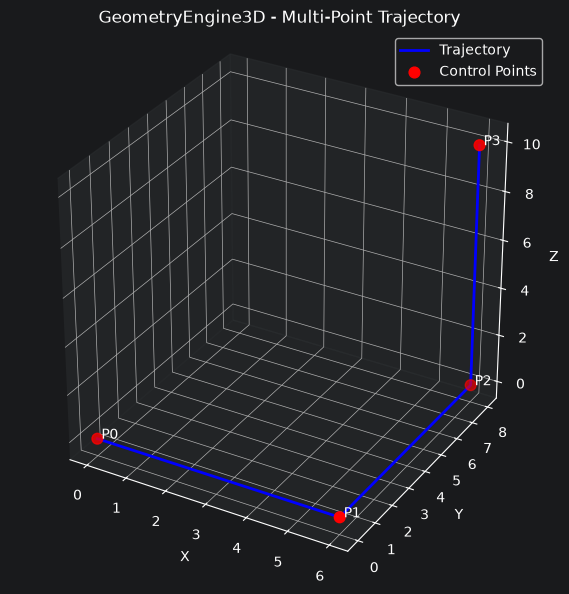

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Generate 100 positions along the trajectory
t_values = np.linspace(0, 1, 100)
positions = [path.position(t) for t in t_values]

# Extract coordinates
x = [p.x for p in positions]
y = [p.y for p in positions]
z = [p.z for p in positions]

# Extract control points
px = [p.x for p in points]
py = [p.y for p in points]
pz = [p.z for p in points]

# Create 3D visualization
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, color="blue", linewidth=2, label="Trajectory")
ax.scatter(px, py, pz, color="red", s=60, label="Control Points")

# Label control points
for i, point in enumerate(points):
    ax.text(point.x, point.y, point.z, f" P{i}")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("GeometryEngine3D - Multi-Point Trajectory")

ax.legend()
ax.set_box_aspect((1, 1, 1))

plt.show()

In [4]:
# Calculate the length of each trajectory segment
segment_lengths = []

for i in range(len(points) - 1):
    distance = points[i].distance_to(points[i + 1])
    segment_lengths.append(distance)

    print(f"Segment P{i} -> P{i+1}: {distance:.2f}")

# Calculate total trajectory length
total_length = sum(segment_lengths)

print(f"\nTotal trajectory length: {total_length:.2f}")

Segment P0 -> P1: 6.00
Segment P1 -> P2: 8.00
Segment P2 -> P3: 10.00

Total trajectory length: 24.00


In [5]:
# Assume a total travel time of 1 second
total_time = 1.0

segment_count = len(points) - 1
segment_time = total_time / segment_count

print("Velocity analysis:\n")

for i, length in enumerate(segment_lengths):
    speed = length / segment_time

    print(
        f"Segment P{i} -> P{i+1}: "
        f"speed = {speed:.2f} units/s"
    )

Velocity analysis:

Segment P0 -> P1: speed = 18.00 units/s
Segment P1 -> P2: speed = 24.00 units/s
Segment P2 -> P3: speed = 30.00 units/s


## 4. Experimental Results and Analysis

### 4.1 Trajectory Length

The experiment uses four control points connected by three
straight line segments.

The calculated segment lengths are:

| Segment | Length |
|---------|--------|
| P0 → P1 | 6 |
| P1 → P2 | 8 |
| P2 → P3 | 10 |
| **Total** | **24** |

The total trajectory length is calculated as:

$$
L = \sum_{i=0}^{n-1} \|P_{i+1}-P_i\|
$$

For the selected control points:

$$
L = 6 + 8 + 10 = 24
$$

### 4.2 Velocity Analysis

The current MultiPointPath3D implementation assigns an equal
parameter interval to each segment.

For this experiment, we assume a total travel time of one second.

Each segment therefore receives:

$$
\Delta t = \frac{1}{3}\text{ s}
$$

The speed along each segment is calculated using:

$$
v_i = \frac{L_i}{\Delta t}
$$

The calculated speeds are:

| Segment | Speed (units/s) |
|---------|-----------------|
| P0 → P1 | 18 |
| P1 → P2 | 24 |
| P2 → P3 | 30 |

The results demonstrate that equal time intervals do not
guarantee constant speed when segment lengths are different.

### 4.3 Evaluation of the Hypothesis

The experiment supports the hypothesis that piecewise linear
interpolation can construct a continuous trajectory through
a finite sequence of control points.

The Python implementation successfully calculates intermediate
positions and passes through the specified control points.

The 3D visualization confirms the geometric structure of
the trajectory.

However, the experiment also reveals two limitations:

1. The speed is not constant when different segment lengths
   are assigned equal travel times.

2. The trajectory contains sharp changes in direction at
   intermediate control points.

These limitations are important when considering applications
in robotics, drone navigation, and automated manufacturing.